Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

C:\Users\tlasharr\AppData\Local\Temp\ipykernel_31084\624740983.py:39: RuntimeWarning: Mean of empty slice
  mean_ndvi = [np.nanmean(ndvi_data[i, :, :]) for i in range(ndvi_data.shape[0])]


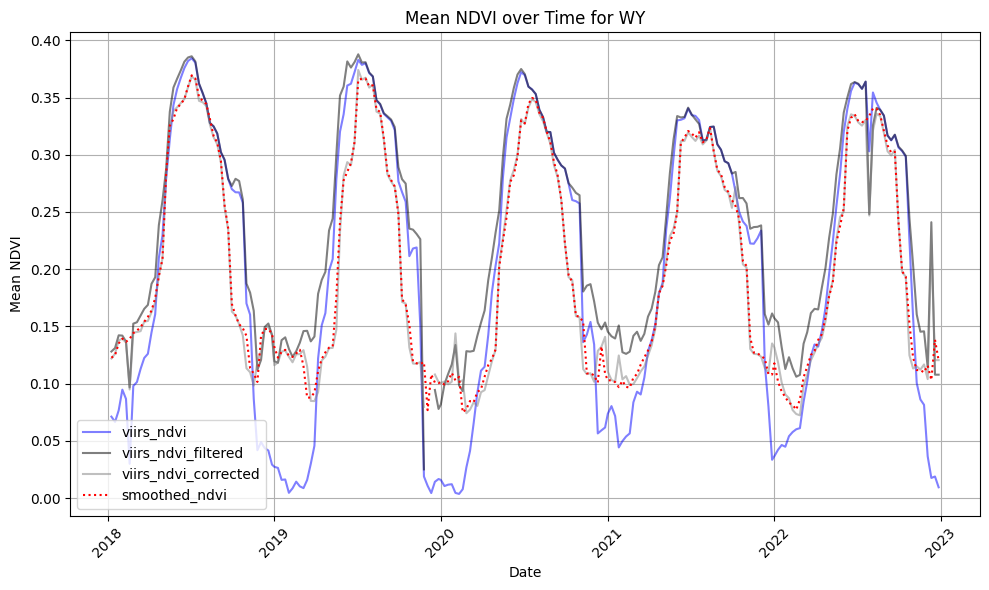

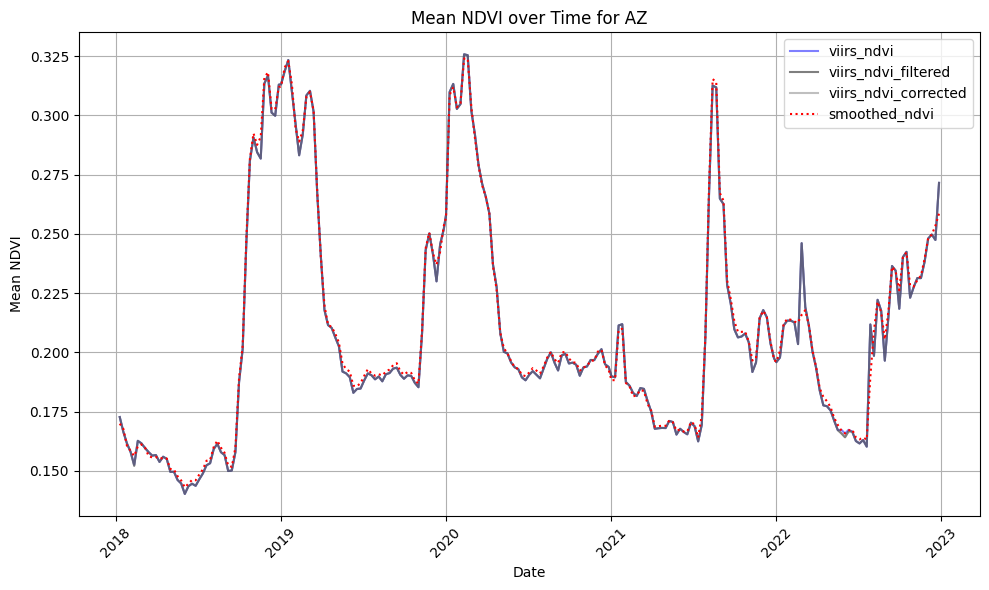

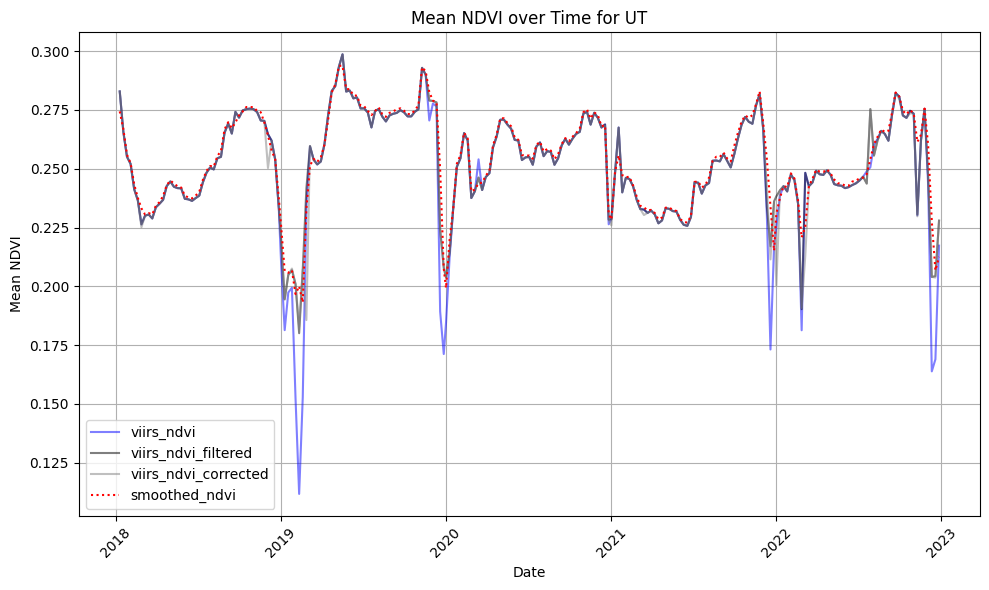

In [16]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from datetime import datetime

# Define the directories for AZ and WY
base_dir = r'H:\My Drive\DroughtSurfing'
locations = ['WY', 'AZ', 'UT']

# Define file paths for the exported GeoTIFFs within each directory
ndvi_file_names = [
    'viirs_ndvi.tif',
    'viirs_ndvi_filtered.tif',
    'viirs_ndvi_corrected.tif',
    'smoothed_ndvi.tif'
]

# Function to extract dates from the band names (assuming format: YYYY_MM_DD_NDVI)
def extract_dates(band_names):
    dates = []
    for name in band_names:
        # Extract the date part from the name using regex
        match = re.search(r'(\d{4}_\d{2}_\d{2})', name)
        if match:
            date_str = match.group(1)
            # Convert string to datetime object
            date_obj = datetime.strptime(date_str, '%Y_%m_%d')
            dates.append(date_obj)
    return dates

# Function to read NDVI data and calculate the mean NDVI over time
def read_ndvi_data(ndvi_path):
    with rasterio.open(ndvi_path) as src:
        ndvi_data = src.read()  # Read all bands (layers) in the stack
        band_names = src.descriptions  # Retrieve layer names (should contain dates)
        dates = extract_dates(band_names)
        mean_ndvi = [np.nanmean(ndvi_data[i, :, :]) for i in range(ndvi_data.shape[0])]
    return dates, mean_ndvi

# Plot each location (AZ and WY) on a separate plot
for location in locations:
    plt.figure(figsize=(10, 6))
    tiff_dir = os.path.join(base_dir, location)

    # Define colors or line styles for different NDVI products
    styles = ['-', '-', '-', ':']
    colors = ['blue', 'black', 'gray', 'red']
    alphas = [0.5, 0.5, 0.5, 1]

    for i, file_name in enumerate(ndvi_file_names):
        ndvi_path = os.path.join(tiff_dir, file_name)
        dates, mean_ndvi = read_ndvi_data(ndvi_path)
        
        # Plot NDVI for each product in the same plot, different line styles
        plt.plot(dates, mean_ndvi, label=f"{file_name.replace('.tif', '')}", linestyle=styles[i], color = colors[i], alpha = alphas[i])

    # Add labels, title, and grid for each location
    plt.title(f'Mean NDVI over Time for {location}')
    plt.xlabel('Date')
    plt.ylabel('Mean NDVI')
    plt.legend(loc='best')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()

    # Show each plot separately
    plt.show()